Cell 1: settings

In [1]:
import numpy as np
import pandas as pd

SEED = 42
rng = np.random.default_rng(SEED)   # one random generator for the whole notebook

HISTORY_START = pd.Timestamp("2021-01-01")   # Friday, like a real extract
HISTORY_END   = pd.Timestamp("2024-12-29")   # Sunday: closes the last full week

# Why a seed: the generator uses random numbers. A fixed seed makes them the same every run,
#  so your data and results can be reproduced exactly.


In [2]:
days = pd.date_range(HISTORY_START, HISTORY_END, freq="D")
print("days:", len(days))
print("first:", days[0].date(), days[0].day_name())
print("last: ", days[-1].date(), days[-1].day_name())


days: 1459
first: 2021-01-01 Friday
last:  2024-12-29 Sunday


Why 1459: 365 + 365 + 365 days for 2021–2023, plus 364 for 2024 (a leap year of 366 days, minus 30–31 Dec). Without the 3-day stub (Fri 1 – Sun 3 Jan 2021), that's 1456 days = exactly 208 complete Monday–Sunday weeks.

In [3]:
provinces = pd.DataFrame(
    [
        ("SP", "São Paulo",         "Sudeste"),
        ("RJ", "Rio de Janeiro",    "Sudeste"),
        ("MG", "Minas Gerais",      "Sudeste"),
        ("RS", "Rio Grande do Sul", "Sul"),
        ("PR", "Paraná",            "Sul"),
        ("SC", "Santa Catarina",    "Sul"),
        ("BA", "Bahia",             "Nordeste"),
        ("PE", "Pernambuco",        "Nordeste"),
        ("CE", "Ceará",             "Nordeste"),
    ],
    columns=["province", "province_name", "region"],
)
provinces


,province,province_name,region
0,SP,São Paulo,Sudeste
1,RJ,Rio de Janeiro,Sudeste
2,MG,Minas Gerais,Sudeste
3,RS,Rio Grande do Sul,Sul
4,PR,Paraná,Sul
5,SC,Santa Catarina,Sul
6,BA,Bahia,Nordeste
7,PE,Pernambuco,Nordeste
8,CE,Ceará,Nordeste


In [4]:
brands = {   # brand: popularity (1.0 = biggest)
    "BRAHMA": 1.0, "SKOL": 0.9, "ANTARCTICA": 0.6, "BUDWEISER": 0.5,
    "ORIGINAL": 0.4, "STELLA ARTOIS": 0.3, "CORONA": 0.3, "SPATEN": 0.25,
}
packs = [    # pack, container, size_ml, units_per_case, returnable, popularity
    ("LATA 269ML",      "can",    269,   15, False, 0.7),
    ("LATA 350ML",      "can",    350,   12, False, 1.0),
    ("LATA 473ML",      "can",    473,   12, False, 0.6),
    ("LONG NECK 330ML", "bottle", 330,   24, False, 0.4),
    ("GARRAFA 600ML",   "bottle", 600,   24, True,  0.8),
    ("BARRIL 30L",      "keg",    30000,  1, True,  0.3),
]

rows = []
for brand, brand_pop in brands.items():
    for pack, container, size_ml, upc, returnable, pack_pop in packs:
        rows.append({
            "brand": brand, "pack": pack, "container": container,
            "size_ml": size_ml, "units_per_case": upc, "returnable": returnable,
            "popularity": round(brand_pop * pack_pop, 3),
        })
combos = pd.DataFrame(rows)
print(combos.shape)


(48, 7)


In [5]:
keep = rng.choice(len(combos), size=40, replace=False)        # drop 8 combinations at random
skus = combos.iloc[np.sort(keep)].reset_index(drop=True)

codes = rng.choice(np.arange(10000, 100000), size=40, replace=False)
skus.insert(0, "sku_id", codes.astype(str))                    # TEXT, as the contract says
skus.insert(1, "sku_name", skus["brand"] + " " + skus["pack"])
skus.head(8)


,sku_id,sku_name,brand,pack,container,size_ml,units_per_case,returnable,popularity
0,73458,BRAHMA LATA 269ML,BRAHMA,LATA 269ML,can,269,15,False,0.70
1,66657,BRAHMA LATA 350ML,BRAHMA,LATA 350ML,can,350,12,False,1.00
2,84879,BRAHMA LATA 473ML,BRAHMA,LATA 473ML,can,473,12,False,0.60
3,69829,BRAHMA LONG NECK 330ML,BRAHMA,LONG NECK 330ML,bottle,330,24,False,0.40
4,34938,BRAHMA BARRIL 30L,BRAHMA,BARRIL 30L,keg,30000,1,True,0.30
5,94591,SKOL LATA 350ML,SKOL,LATA 350ML,can,350,12,False,0.90
6,80223,SKOL LONG NECK 330ML,SKOL,LONG NECK 330ML,bottle,330,24,False,0.36
7,27988,SKOL GARRAFA 600ML,SKOL,GARRAFA 600ML,bottle,600,24,True,0.72


In [6]:
skus["launch_date"] = pd.NaT          # NaT = "no date" (sold before history / still active)
skus["discontinue_date"] = pd.NaT

picked = rng.choice(40, size=7, replace=False)
launch_idx, disc_idx = picked[:4], picked[4:]
skus.loc[launch_idx, "launch_date"] = pd.to_datetime(
    ["2022-03-07", "2022-10-03", "2023-06-05", "2024-04-01"])        # Mondays: launch at a week start
skus.loc[disc_idx, "discontinue_date"] = pd.to_datetime(
    ["2022-12-25", "2023-08-27", "2024-06-30"])                      # Sundays: stop at a week end

skus.loc[skus["launch_date"].notna() | skus["discontinue_date"].notna(),
         ["sku_id", "sku_name", "launch_date", "discontinue_date"]]


,sku_id,sku_name,launch_date,discontinue_date
15,73000,BUDWEISER LATA 269ML,2023-06-05,NaT
16,32093,BUDWEISER LATA 350ML,2024-04-01,NaT
17,24456,BUDWEISER LATA 473ML,NaT,2022-12-25
24,51300,ORIGINAL LONG NECK 330ML,2022-03-07,NaT
27,90806,STELLA ARTOIS LATA 350ML,NaT,2023-08-27
35,35942,SPATEN LATA 269ML,2022-10-03,NaT
38,31554,SPATEN GARRAFA 600ML,NaT,2024-06-30


In [7]:
print(skus.shape)
print(skus["sku_id"].is_unique)
print(skus["container"].value_counts())
print(skus.dtypes)


(40, 11)
True
container
can       20
bottle    12
keg        8
Name: count, dtype: int64
sku_id                         str
sku_name                       str
brand                          str
pack                           str
container                      str
size_ml                      int64
units_per_case               int64
returnable                    bool
popularity                 float64
launch_date         datetime64[ns]
discontinue_date    datetime64[ns]
dtype: object


In [8]:
province_size = {          # relative market size (SP = 1.0)
    "SP": 1.00, "MG": 0.45, "RJ": 0.40,
    "RS": 0.30, "PR": 0.28, "SC": 0.18,
    "BA": 0.30, "PE": 0.20, "CE": 0.18,
}
provinces["size"] = provinces["province"].map(province_size)
provinces


,province,province_name,region,size
0,SP,São Paulo,Sudeste,1.00
1,RJ,Rio de Janeiro,Sudeste,0.40
2,MG,Minas Gerais,Sudeste,0.45
3,RS,Rio Grande do Sul,Sul,0.30
4,PR,Paraná,Sul,0.28
5,SC,Santa Catarina,Sul,0.18
6,BA,Bahia,Nordeste,0.30
7,PE,Pernambuco,Nordeste,0.20
8,CE,Ceará,Nordeste,0.18


In [9]:
series = provinces[["province", "region", "size"]].merge(
    skus[["sku_id", "pack", "popularity"]], how="cross")      # all 9 × 40 = 360 pairs
print(series.shape)

core   = series["popularity"] >= 0.5                          # core SKUs: sold everywhere
p_sell = (0.35 + 0.6 * series["size"]).clip(upper=0.95)       # bigger state → more likely stocked
series["active"] = core | (rng.random(len(series)) < p_sell)

print("active:", series["active"].sum(), "of", len(series))
series.groupby("province")["active"].sum().reindex(provinces["province"])


(360, 6)
active: 231 of 360


province
SP    38
RJ    31
MG    26
RS    22
PR    30
SC    20
BA    21
PE    22
CE    21
Name: active, dtype: int64

In [10]:
series = series[series["active"]].drop(columns="active").reset_index(drop=True)

SCALE_HL = 1200                                   # SP × best-selling SKU ≈ 1,200 HL/week
regional_taste = np.where(
    (series["region"] == "Nordeste") & (series["pack"] == "GARRAFA 600ML"), 1.5, 1.0)
noise = rng.lognormal(mean=0.0, sigma=0.4, size=len(series))   # no two series identical

series["base_hl_week"] = (
    SCALE_HL * series["size"] * series["popularity"] * regional_taste * noise
).round(1)


In [11]:
print(series["base_hl_week"].describe().round(1))
print("total HL/week:", series["base_hl_week"].sum().round(0))
print("series under 20 HL/week:", (series["base_hl_week"] < 20).sum())
series.sort_values("base_hl_week", ascending=False).head(5)


count     231.0
mean      189.7
std       211.3
min        11.0
25%        65.9
50%       116.0
75%       225.4
max      1671.9
Name: base_hl_week, dtype: float64
total HL/week: 43824.0
series under 20 HL/week: 9


,province,region,size,sku_id,pack,popularity,base_hl_week
0,SP,Sudeste,1.00,73458,LATA 269ML,0.70,1671.9
7,SP,Sudeste,1.00,27988,GARRAFA 600ML,0.72,1252.5
5,SP,Sudeste,1.00,94591,LATA 350ML,0.90,1024.8
2,SP,Sudeste,1.00,84879,LATA 473ML,0.60,842.5
73,MG,Sudeste,0.45,94591,LATA 350ML,0.90,838.6


In [12]:
series["brand"] = series["sku_id"].map(skus.set_index("sku_id")["brand"])

premium = {"STELLA ARTOIS", "CORONA", "SPATEN", "BUDWEISER"}
brand_drift = np.where(series["brand"].isin(premium), 0.05, 0.0)       # premium grows ~5%/year
series["trend_per_year"] = (brand_drift + rng.normal(0.0, 0.03, len(series))).round(3)

series.groupby(series["brand"].isin(premium))["trend_per_year"].mean().round(3)


brand
False   -0.000
True     0.046
Name: trend_per_year, dtype: float64

In [13]:
SEASON_PEAK_DOY = 15                                     # day of year 15 = mid-January
region_amp = {"Sul": 0.35, "Sudeste": 0.25, "Nordeste": 0.10}
series["season_amp"] = (
    series["region"].map(region_amp) * rng.uniform(0.8, 1.2, len(series))
).round(3)

series.groupby("region")["season_amp"].agg(["min", "mean", "max"]).round(3)


,min,mean,max
region,,,
Nordeste,0.080,0.101,0.120
Sudeste,0.200,0.250,0.299
Sul,0.283,0.358,0.419


In [14]:
grid = series[["province", "sku_id", "base_hl_week", "trend_per_year", "season_amp"]].merge(
    pd.DataFrame({"date": days}), how="cross")                 # every series × every day

t_years = (grid["date"] - HISTORY_START).dt.days / 365.25     # years since the start
doy     = grid["date"].dt.dayofyear

grid["trend_mult"]  = (1 + grid["trend_per_year"]) ** t_years
grid["season_mult"] = 1 + grid["season_amp"] * np.cos(2 * np.pi * (doy - SEASON_PEAK_DOY) / 365.25)
grid["expected_hl_day"] = grid["base_hl_week"] / 7 * grid["trend_mult"] * grid["season_mult"]

print(grid.shape)
grid.head()


(337029, 9)


C:\Users\haris\AppData\Local\Temp\ipykernel_33928\4029513242.py:5: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  doy     = grid["date"].dt.dayofyear


,province,sku_id,base_hl_week,trend_per_year,season_amp,date,trend_mult,season_mult,expected_hl_day
0,SP,73458,1671.9,0.036,0.285,2021-01-01,1.000000,1.276775,304.948525
1,SP,73458,1671.9,0.036,0.285,2021-01-02,1.000097,1.277903,305.247578
2,SP,73458,1671.9,0.036,0.285,2021-01-03,1.000194,1.278949,305.527040
3,SP,73458,1671.9,0.036,0.285,2021-01-04,1.000291,1.279913,305.786833
4,SP,73458,1671.9,0.036,0.285,2021-01-05,1.000387,1.280793,306.026882


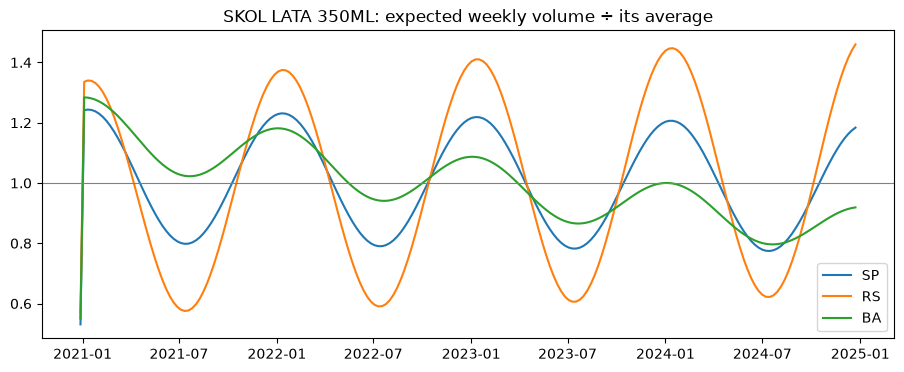

In [15]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(11, 4))
for prov in ["SP", "RS", "BA"]:
    s = grid[(grid["province"] == prov) & (grid["sku_id"] == "94591")]       # SKOL LATA 350ML (core)
    week_start = s["date"] - pd.to_timedelta(s["date"].dt.day_of_week, unit="D")
    weekly = s.groupby(week_start)["expected_hl_day"].sum()
    ax.plot(weekly.index, weekly / weekly.mean(), label=prov)

ax.axhline(1, color="grey", lw=0.8)
ax.set_title("SKOL LATA 350ML: expected weekly volume ÷ its average")
ax.legend()
plt.show()


In [ ]:
from pathlib import Path
from demandfcst.config import PROJECT_ROOT as ROOT                      # the notebook runs inside notebooks/
print(ROOT)

raw = pd.read_csv(ROOT / "data/raw/source/weather_source.csv")
weather = raw.rename(columns={
    "Sales Domain.[Province]": "province",
    "Time.[FiscalWeek]":       "week_start",
    "Max Weighted Temp":       "temp_max_f",
    "Min Weighted Temp":       "temp_min_f",
    "Weighted Temperature":    "temp_avg_f",
    "Weighted Precipitation":  "precipitation",
})
weather = weather[weather["province"].isin(provinces["province"])].copy()   # our 9 states only
weather["week_start"] = pd.to_datetime(weather["week_start"], format="%m/%d/%Y")

for t in ["max", "min", "avg"]:
    weather[f"temp_{t}_c"] = ((weather[f"temp_{t}_f"] - 32) * 5 / 9).round(2)   # °F → °C
weather = weather[["province", "week_start", "temp_max_c", "temp_min_c", "temp_avg_c", "precipitation"]]

print(weather.shape)
print(weather["week_start"].min().date(), "→", weather["week_start"].max().date())
print("all Mondays:", (weather["week_start"].dt.day_of_week == 0).all())
print("duplicate province-weeks:", weather.duplicated(["province", "week_start"]).sum())
weather.groupby("province")["temp_avg_c"].mean().round(1)


c:\Harish\demand_forecasting\demand_forecasting_abi\demand_forecasting
(3675, 6)
2016-12-26 → 2024-10-28
all Mondays: True
duplicate province-weeks: 0


province
BA    25.3
CE    26.9
MG    22.4
PE    25.7
PR    20.0
RJ    24.1
RS    19.9
SC    20.7
SP    22.9
Name: temp_avg_c, dtype: float64

In [17]:
all_weeks = pd.date_range(weather["week_start"].min(), weather["week_start"].max(), freq="7D")
full_index = pd.MultiIndex.from_product([provinces["province"], all_weeks],
                                        names=["province", "week_start"])
weather = weather.set_index(["province", "week_start"]).reindex(full_index)
print("missing province-weeks:", weather["temp_avg_c"].isna().sum())

weather = (weather.groupby(level="province")
                  .transform(lambda s: s.interpolate(limit_direction="both"))
                  .reset_index())
print("after filling:", weather["temp_avg_c"].isna().sum(), "| rows:", len(weather))


missing province-weeks: 15
after filling: 0 | rows: 3690


In [18]:
weather["woy"] = weather["week_start"].dt.isocalendar().week.astype(int).clip(upper=52)  # week of year

cols = ["temp_max_c", "temp_min_c", "temp_avg_c", "precipitation"]
normals = weather.groupby(["province", "woy"])[cols].mean().add_suffix("_normal")
weather = weather.join(normals, on=["province", "woy"])
weather["anomaly_c"] = (weather["temp_avg_c"] - weather["temp_avg_c_normal"]).round(2)

weather.groupby("province")["anomaly_c"].agg(["mean", "std", "min", "max"]).round(2)


,mean,std,min,max
province,,,,
BA,-0.0,0.97,-2.94,3.09
CE,0.0,0.97,-3.18,2.85
MG,-0.0,1.18,-4.03,5.48
PE,0.0,0.85,-2.74,2.30
PR,-0.0,1.85,-6.96,5.13
RJ,-0.0,1.49,-7.09,5.49
RS,-0.0,1.94,-6.10,5.71
SC,-0.0,1.86,-6.12,5.59
SP,0.0,1.51,-5.73,5.13


In [19]:
last_real = weather["week_start"].max()
future_weeks = pd.date_range(last_real + pd.Timedelta(days=7),
                             HISTORY_END - pd.Timedelta(days=6), freq="7D")

fut = pd.MultiIndex.from_product([provinces["province"], future_weeks],
                                 names=["province", "week_start"]).to_frame(index=False)
fut["woy"] = fut["week_start"].dt.isocalendar().week.astype(int).clip(upper=52)
fut = fut.join(normals, on=["province", "woy"])

anom_sd = weather.groupby("province")["anomaly_c"].std()
fut["anomaly_c"] = (rng.normal(0, 1, len(fut)) * fut["province"].map(anom_sd)).round(2)
for t in ["max", "min", "avg"]:
    fut[f"temp_{t}_c"] = (fut[f"temp_{t}_c_normal"] + fut["anomaly_c"]).round(2)  # normal + surprise
fut["precipitation"] = fut["precipitation_normal"]

weather["is_synthetic"] = False
fut["is_synthetic"] = True
weather = pd.concat([weather, fut[weather.columns]], ignore_index=True)

print(len(future_weeks), "synthetic weeks:", future_weeks[0].date(), "→", future_weeks[-1].date())
print(weather.groupby("is_synthetic").size())


8 synthetic weeks: 2024-11-04 → 2024-12-23
is_synthetic
False    3690
True       72
dtype: int64


In [20]:
series["weather_beta"] = rng.uniform(0.02, 0.04, len(series)).round(3)   # +2–4% per °C above normal

grid["week_start"] = grid["date"] - pd.to_timedelta(grid["date"].dt.day_of_week, unit="D")
grid = grid.merge(weather[["province", "week_start", "anomaly_c"]],
                  on=["province", "week_start"], how="left")
grid = grid.merge(series[["province", "sku_id", "weather_beta"]], on=["province", "sku_id"])

grid["weather_mult"] = (1 + grid["weather_beta"] * grid["anomaly_c"]).clip(0.7, 1.3)
grid["expected_hl_day"] = (grid["base_hl_week"] / 7 * grid["trend_mult"]
                           * grid["season_mult"] * grid["weather_mult"])

print(grid.shape)
print("days without weather:", grid["anomaly_c"].isna().sum())
grid["weather_mult"].describe().round(3)


(337029, 13)
days without weather: 0


count    337029.000
mean          1.002
std           0.049
min           0.716
25%           0.977
50%           1.005
75%           1.031
max           1.224
Name: weather_mult, dtype: float64

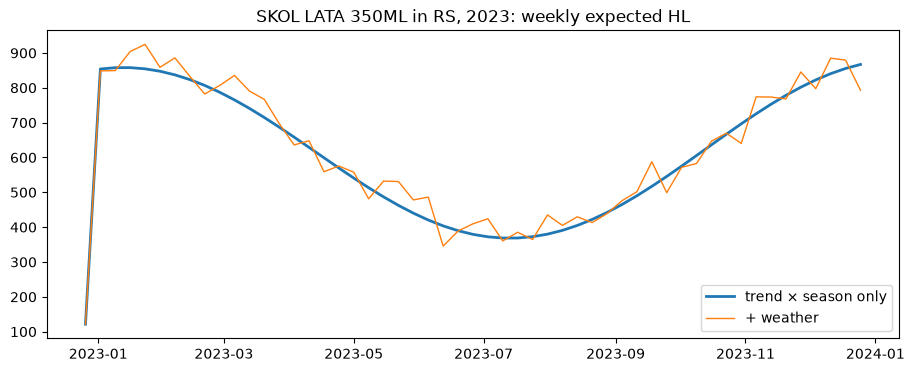

In [21]:
s = grid[(grid["province"] == "RS") & (grid["sku_id"] == "94591") & (grid["date"].dt.year == 2023)]
with_w    = s.groupby("week_start")["expected_hl_day"].sum()
without_w = (s["expected_hl_day"] / s["weather_mult"]).groupby(s["week_start"]).sum()

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(without_w.index, without_w, label="trend × season only", lw=2)
ax.plot(with_w.index, with_w, label="+ weather", lw=1)
ax.set_title("SKOL LATA 350ML in RS, 2023: weekly expected HL")
ax.legend()
plt.show()


In [22]:
def easter_sunday(year):
    """Gregorian Easter date (Meeus/Jones/Butcher algorithm)."""
    a = year % 19
    b, c = divmod(year, 100)
    d, e = divmod(b, 4)
    f = (b + 8) // 25
    g = (b - f + 1) // 3
    h = (19 * a + b - d - g + 15) % 30
    i, k = divmod(c, 4)
    l = (32 + 2 * e + 2 * i - h - k) % 7
    m = (a + 11 * h + 22 * l) // 451
    month, day = divmod(h + l - 7 * m + 114, 31)
    return pd.Timestamp(year, month, day + 1)

STATE_HOLIDAYS = [   # (MM-DD, province, name). Approximate placeholders until a real calendar is supplied
    ("07-09", "SP", "Revolução Constitucionalista"),
    ("04-23", "RJ", "São Jorge"),
    ("09-20", "RS", "Revolução Farroupilha"),
    ("12-19", "PR", "Emancipação do Paraná"),
    ("08-11", "SC", "Data Magna de Santa Catarina"),
    ("07-02", "BA", "Independência da Bahia"),
    ("03-06", "PE", "Revolução Pernambucana"),
    ("03-25", "CE", "Data Magna do Ceará"),
    ("06-24", "BA", "São João"), ("06-24", "PE", "São João"), ("06-24", "CE", "São João"),
]

def brazil_holidays(year):
    e = easter_sunday(year)
    rows = [
        (pd.Timestamp(f"{year}-01-01"), "BR", "Confraternização Universal"),
        (e - pd.Timedelta(days=48),     "BR", "Carnaval"),            # Monday
        (e - pd.Timedelta(days=47),     "BR", "Carnaval"),            # Tuesday
        (e - pd.Timedelta(days=2),      "BR", "Sexta-feira Santa"),
        (pd.Timestamp(f"{year}-04-21"), "BR", "Tiradentes"),
        (pd.Timestamp(f"{year}-05-01"), "BR", "Dia do Trabalho"),
        (e + pd.Timedelta(days=60),     "BR", "Corpus Christi"),
        (pd.Timestamp(f"{year}-09-07"), "BR", "Independência"),
        (pd.Timestamp(f"{year}-10-12"), "BR", "Nossa Senhora Aparecida"),
        (pd.Timestamp(f"{year}-11-02"), "BR", "Finados"),
        (pd.Timestamp(f"{year}-11-15"), "BR", "Proclamação da República"),
        (pd.Timestamp(f"{year}-12-25"), "BR", "Natal"),
    ]
    if year >= 2024:                                                  # national holiday from 2024
        rows.append((pd.Timestamp(f"{year}-11-20"), "BR", "Consciência Negra"))
    rows += [(pd.Timestamp(f"{year}-{md}"), prov, name) for md, prov, name in STATE_HOLIDAYS]
    return pd.DataFrame(rows, columns=["date", "province", "holiday_name"])

holidays = pd.concat([brazil_holidays(y) for y in range(2020, 2031)], ignore_index=True)
print(holidays.shape)
holidays[holidays["holiday_name"] == "Carnaval"].query("date.dt.year <= 2025")


(260, 3)


,date,province,holiday_name
1,2020-02-24,BR,Carnaval
2,2020-02-25,BR,Carnaval
24,2021-02-15,BR,Carnaval
25,2021-02-16,BR,Carnaval
47,2022-02-28,BR,Carnaval
48,2022-03-01,BR,Carnaval
70,2023-02-20,BR,Carnaval
71,2023-02-21,BR,Carnaval
93,2024-02-12,BR,Carnaval
94,2024-02-13,BR,Carnaval


In [23]:
EVENT_PROFILES = {      # week offset from the event's week → uplift on sell-in
    "Carnaval":  {-2: 0.25, -1: 0.40, 0: 0.10, 1: -0.20},
    "Natal":     {-2: 0.20, -1: 0.30, 0: 0.15, 1: 0.05, 2: -0.15},   # +1 = New Year week, +2 = January dip
    "São João":  {-1: 0.30, 0: 0.10, 1: -0.10},
    "Confraternização Universal": {},          # already covered by the Natal profile
}
DEFAULT_PROFILE   = {-1: 0.04, 0: 0.06}       # ordinary holiday: long-weekend bump
CARNIVAL_STRENGTH = {"Sudeste": 1.0, "Sul": 0.6, "Nordeste": 1.3}
YEAR_STRENGTH     = {("Carnaval", 2021): 0.2}  # 2021 street Carnival cancelled (COVID)
region_of = provinces.set_index("province")["region"]


In [24]:
hol = holidays.copy()
hol["event_week"] = hol["date"] - pd.to_timedelta(hol["date"].dt.day_of_week, unit="D")

national = hol[hol["province"] == "BR"].drop(columns="province").merge(provinces[["province"]], how="cross")
hol_p = pd.concat([hol[hol["province"] != "BR"], national], ignore_index=True)    # BR → all 9 states
events = hol_p.drop_duplicates(["holiday_name", "province", "event_week"])        # Carnival Mon+Tue = 1 event

rows = []
for ev in events.itertuples():
    profile  = EVENT_PROFILES.get(ev.holiday_name, DEFAULT_PROFILE)
    strength = YEAR_STRENGTH.get((ev.holiday_name, ev.event_week.year), 1.0)
    if ev.holiday_name == "Carnaval":
        strength *= CARNIVAL_STRENGTH[region_of[ev.province]]
    for offset, uplift in profile.items():
        rows.append((ev.province, ev.event_week + pd.Timedelta(weeks=offset), uplift * strength))

uplifts = pd.DataFrame(rows, columns=["province", "week_start", "uplift"])
holiday_effect = uplifts.groupby(["province", "week_start"], as_index=False)["uplift"].sum()
holiday_effect["holiday_mult"] = (1 + holiday_effect["uplift"]).clip(0.6, 1.8)

print(holiday_effect.shape)
holiday_effect.query("province == 'BA' and week_start.dt.year == 2023").head(8)


(2588, 4)


,province,week_start,uplift,holiday_mult
77,BA,2023-01-02,-0.150,0.850
78,BA,2023-02-06,0.325,1.325
79,BA,2023-02-13,0.520,1.520
80,BA,2023-02-20,0.130,1.130
81,BA,2023-02-27,-0.260,0.740
82,BA,2023-03-27,0.040,1.040
83,BA,2023-04-03,0.060,1.060
84,BA,2023-04-10,0.040,1.040


In [25]:
grid = grid.drop(columns=["holiday_mult"], errors="ignore")                       # safe to re-run
grid = grid.merge(holiday_effect[["province", "week_start", "holiday_mult"]],
                  on=["province", "week_start"], how="left")
grid["holiday_mult"] = grid["holiday_mult"].fillna(1.0)          # weeks with no event: no effect

grid["expected_hl_day"] = (grid["base_hl_week"] / 7 * grid["trend_mult"] * grid["season_mult"]
                           * grid["weather_mult"] * grid["holiday_mult"])

print(grid.shape)
print("share of days with a holiday effect:", (grid["holiday_mult"] != 1).mean().round(3))
grid["holiday_mult"].describe().round(3)


(337029, 14)
share of days with a holiday effect: 0.499


count    337029.000
mean          1.038
std           0.088
min           0.740
25%           1.000
50%           1.000
75%           1.060
max           1.560
Name: holiday_mult, dtype: float64

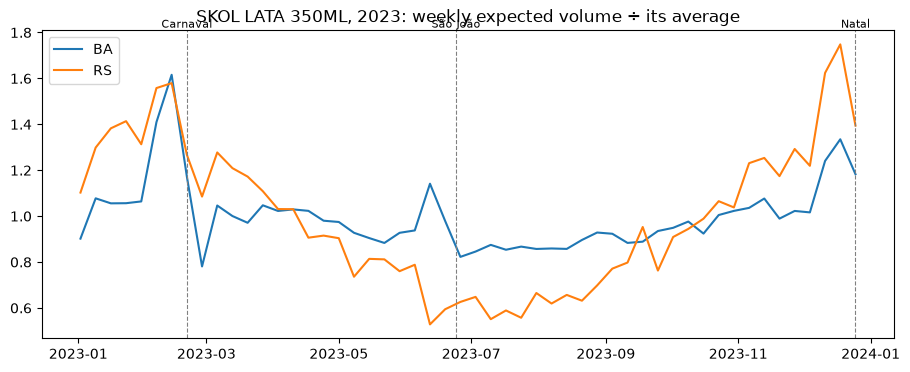

In [26]:
fig, ax = plt.subplots(figsize=(11, 4))
for prov in ["BA", "RS"]:
    s = grid[(grid["province"] == prov) & (grid["sku_id"] == "94591")]
    w = s.groupby("week_start")["expected_hl_day"].sum()
    w = w[(w.index >= "2023-01-02") & (w.index <= "2023-12-25")]       # filter on week_start!
    ax.plot(w.index, w / w.mean(), label=prov)

for d, name in [("2023-02-20", "Carnaval"), ("2023-06-24", "São João"), ("2023-12-25", "Natal")]:
    ax.axvline(pd.Timestamp(d), color="grey", ls="--", lw=0.8)
    ax.text(pd.Timestamp(d), ax.get_ylim()[1], name, ha="center", va="bottom", fontsize=8)
ax.set_title("SKOL LATA 350ML, 2023: weekly expected volume ÷ its average")
ax.legend()
plt.show()


In [27]:
promo_brands = {"BRAHMA", "SKOL", "ANTARCTICA", "BUDWEISER", "ORIGINAL"}
has_promo = series["brand"].isin(promo_brands) & (rng.random(len(series)) < 0.7)
series["promo_rate"] = np.where(has_promo, rng.uniform(1/14, 1/7, len(series)), 0.0).round(3)

print("series with promotions:", (series["promo_rate"] > 0).sum(), "of", len(series))
print("average weeks between promos:", (1 / series.loc[series["promo_rate"] > 0, "promo_rate"]).mean().round(1))


series with promotions: 103 of 231
average weeks between promos: 9.8


In [28]:
weeks = pd.date_range("2020-12-28", HISTORY_END - pd.Timedelta(days=6), freq="7D")   # all Mondays

promo = (series.loc[series["promo_rate"] > 0, ["province", "sku_id", "promo_rate"]]
         .merge(pd.DataFrame({"week_start": weeks}), how="cross")
         .sort_values(["province", "sku_id", "week_start"])
         .reset_index(drop=True))
promo["is_promo"] = rng.random(len(promo)) < promo["promo_rate"]

prev = promo.groupby(["province", "sku_id"])["is_promo"]
too_soon = prev.shift(1, fill_value=False) | prev.shift(2, fill_value=False)
promo["is_promo"] = promo["is_promo"] & ~too_soon                    # no promo within 2 weeks of the last

promo_events = promo[promo["is_promo"]].copy()
promo_events["uplift"] = rng.uniform(0.4, 1.0, len(promo_events)).round(2)    # depth: +40% … +100%
print(len(weeks), "weeks |", len(promo_events), "promotions")
print("per promoting series:", promo_events.groupby(["province", "sku_id"]).size().describe().round(1))


209 weeks | 1797 promotions
per promoting series: count    103.0
mean      17.4
std        4.3
min        5.0
25%       15.0
50%       17.0
75%       21.0
max       29.0
dtype: float64


In [29]:
PROMO_PROFILE = {0: 1.0, 1: -0.4, 2: -0.15}       # share of the uplift: spike, then sell-through

parts = []
for offset, share in PROMO_PROFILE.items():
    t = promo_events[["province", "sku_id", "week_start", "uplift"]].copy()
    t["week_start"] = t["week_start"] + pd.Timedelta(weeks=offset)
    t["promo_uplift"] = t["uplift"] * share
    parts.append(t)

promo_effect = (pd.concat(parts)
                .groupby(["province", "sku_id", "week_start"], as_index=False)["promo_uplift"].sum())
promo_effect["promo_mult"] = (1 + promo_effect["promo_uplift"]).clip(0.5, 2.2)
promo_effect["promo_mult"].describe().round(2)


count    5391.00
mean        1.10
std         0.44
min         0.60
25%         0.78
50%         0.90
75%         1.54
max         2.00
Name: promo_mult, dtype: float64

In [30]:
grid = grid.drop(columns=["promo_mult"], errors="ignore")                           # safe to re-run
grid = grid.merge(promo_effect[["province", "sku_id", "week_start", "promo_mult"]],
                  on=["province", "sku_id", "week_start"], how="left")
grid["promo_mult"] = grid["promo_mult"].fillna(1.0)

grid["expected_hl_day"] = (grid["base_hl_week"] / 7 * grid["trend_mult"] * grid["season_mult"]
                           * grid["weather_mult"] * grid["holiday_mult"] * grid["promo_mult"])
print(grid.shape)


(337029, 15)


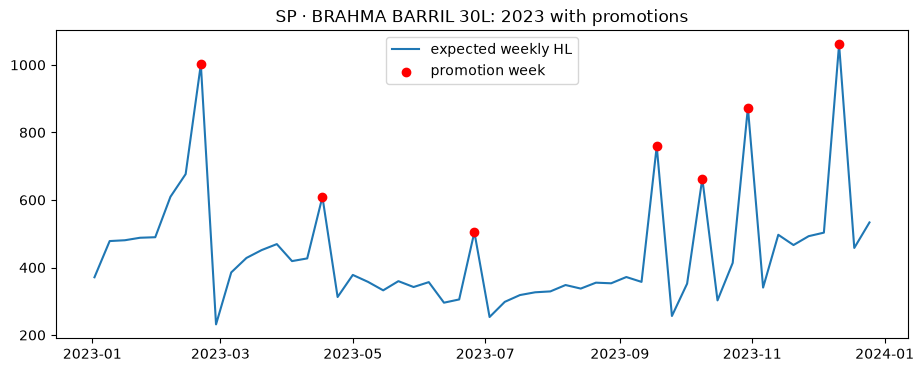

In [31]:
busiest = promo_events[promo_events["province"] == "SP"].groupby("sku_id").size().idxmax()
s = grid[(grid["province"] == "SP") & (grid["sku_id"] == busiest)]
w = s.groupby("week_start")["expected_hl_day"].sum()
w = w[(w.index >= "2023-01-02") & (w.index <= "2023-12-25")]

p = promo_events[(promo_events["province"] == "SP") & (promo_events["sku_id"] == busiest)]
p = p[p["week_start"].isin(w.index)]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(w.index, w, label="expected weekly HL")
ax.scatter(p["week_start"], w.loc[p["week_start"]], color="red", zorder=3, label="promotion week")
ax.set_title(f"SP · {skus.set_index('sku_id').loc[busiest, 'sku_name']}: 2023 with promotions")
ax.legend()
plt.show()


In [32]:
life   = skus.set_index("sku_id")[["launch_date", "discontinue_date"]]
launch = grid["sku_id"].map(life["launch_date"])
disc   = grid["sku_id"].map(life["discontinue_date"])

weeks_since_launch = (grid["date"] - launch).dt.days / 7
ramp = (0.2 + 0.8 * weeks_since_launch / 8).clip(upper=1.0)            # 20% → 100% over 8 weeks

grid["life_mult"] = np.where(launch.notna(), ramp, 1.0)
grid.loc[launch.notna() & (grid["date"] < launch), "life_mult"] = 0.0     # not launched yet
grid.loc[disc.notna() & (grid["date"] > disc), "life_mult"] = 0.0          # discontinued

print("days with no sales due to lifecycle:", (grid["life_mult"] == 0).sum())
grid.loc[grid["sku_id"] == "32093"].groupby("week_start")["life_mult"].mean().loc["2024-03-25":"2024-06-03"].round(2)


days with no sales due to lifecycle: 24087


week_start
2024-03-25    0.00
2024-04-01    0.24
2024-04-08    0.34
2024-04-15    0.44
2024-04-22    0.54
2024-04-29    0.64
2024-05-06    0.74
2024-05-13    0.84
2024-05-20    0.94
2024-05-27    1.00
2024-06-03    1.00
Name: life_mult, dtype: float64

In [33]:
DOW_WEIGHT = {0: 1.15, 1: 1.15, 2: 1.10, 3: 1.15, 4: 1.25, 5: 0.20, 6: 0.0}   # Mon … Sun (shipments)

cal = (pd.DataFrame({"date": pd.date_range("2020-12-28", HISTORY_END, freq="D")})   # starts on a Monday
         .merge(provinces[["province"]], how="cross"))
cal["week_start"] = cal["date"] - pd.to_timedelta(cal["date"].dt.day_of_week, unit="D")
cal["w"] = cal["date"].dt.day_of_week.map(DOW_WEIGHT)

hol_days = hol_p[["province", "date"]].drop_duplicates().assign(is_holiday=True)
cal = cal.merge(hol_days, on=["province", "date"], how="left")
cal["is_holiday"] = cal["is_holiday"].notna()
cal.loc[cal["is_holiday"], "w"] *= 0.1                                   # almost no deliveries on holidays

cal["day_share"] = cal["w"] / cal.groupby(["province", "week_start"])["w"].transform("sum")

print("shares sum to 1 every week:", cal.groupby(["province", "week_start"])["day_share"].sum().round(6).eq(1).all())
cal.groupby(cal["date"].dt.day_name())["day_share"].mean().round(3)


shares sum to 1 every week: True


date
Friday       0.209
Monday       0.191
Saturday     0.034
Sunday       0.000
Thursday     0.192
Tuesday      0.191
Wednesday    0.184
Name: day_share, dtype: float64

In [34]:
grid = grid.drop(columns=["day_share"], errors="ignore")
grid = grid.merge(cal[["province", "date", "day_share"]], on=["province", "date"], how="left")
grid["expected_hl"] = grid["expected_hl_day"] * 7 * grid["day_share"] * grid["life_mult"]

chk = grid[grid["week_start"] >= "2021-01-04"].groupby(["province", "sku_id", "week_start"])
print("weekly totals preserved (life_mult = 1 weeks):",
      np.allclose(chk["expected_hl"].sum()[chk["life_mult"].min() == 1],
                  (chk["expected_hl_day"].mean() * 7)[chk["life_mult"].min() == 1], rtol=0.01))


weekly totals preserved (life_mult = 1 weeks): False


In [35]:
a  = chk["expected_hl"].sum()
b  = chk["expected_hl_day"].mean() * 7
ok = chk["life_mult"].min() == 1

ratio = (a / b)[ok]
print("weeks compared:", len(ratio), "| NaN:", ratio.isna().sum())
print(ratio.describe().round(4))
print("weeks off by more than 1%:", ((ratio - 1).abs() > 0.01).sum())
ratio[(ratio - 1).abs() > 0.01].head(10)


weeks compared: 44448 | NaN: 0
count    44448.0000
mean         1.0000
std          0.0030
min          0.9896
25%          0.9980
50%          1.0000
75%          1.0019
max          1.0095
dtype: float64
weeks off by more than 1%: 3


province  sku_id  week_start
RS        13353   2024-09-16    0.989802
          27988   2024-09-16    0.989643
          44863   2024-09-16    0.989867
dtype: float64

In [36]:
series["container"] = series["sku_id"].map(skus.set_index("sku_id")["container"])

small    = series["base_hl_week"] <= series["base_hl_week"].quantile(0.15)       # smallest 15%
keg_pick = (series["container"] == "keg") & (rng.random(len(series)) < 0.3)     # some kegs
series["sparse"] = small | keg_pick

series["order_prob"] = np.where(series["sparse"], rng.uniform(0.3, 0.7, len(series)), 1.0).round(2)
series["noise_cv"] = np.where(
    series["sparse"],
    np.where(rng.random(len(series)) < 0.5, 0.3, 1.0),                          # intermittent | lumpy
    (0.25 + 3 / np.sqrt(series["base_hl_week"])).clip(upper=0.8),             # big series → steadier
).round(2)

print("sparse series:", series["sparse"].sum(), "of", len(series))
series.groupby("sparse")[["base_hl_week", "order_prob", "noise_cv"]].mean().round(2)


sparse series: 43 of 231


,base_hl_week,order_prob,noise_cv
sparse,,,
False,224.27,1.00,0.50
True,38.63,0.48,0.74


In [37]:
grid = grid.drop(columns=["sparse", "order_prob", "noise_cv", "order_hl", "volume_hl"], errors="ignore")
grid = grid.merge(series[["province", "sku_id", "sparse", "order_prob", "noise_cv"]],
                  on=["province", "sku_id"])

# --- dense series: every delivery day gets expected × random noise ---
grid["volume_hl"] = 0.0
m  = ~grid["sparse"] & (grid["expected_hl"] > 0)
cv = grid.loc[m, "noise_cv"].to_numpy()
grid.loc[m, "volume_hl"] = rng.gamma(1 / cv**2, grid.loc[m, "expected_hl"].to_numpy() * cv**2)

# --- sparse series: some weeks get one order, on one delivery day ---
sp = grid[grid["sparse"]]
wk = sp.groupby(["province", "sku_id", "week_start"], as_index=False).agg(
        expected_week=("expected_hl", "sum"), order_prob=("order_prob", "first"),
        noise_cv=("noise_cv", "first"))
wk["ordered"] = (rng.random(len(wk)) < wk["order_prob"]) & (wk["expected_week"] > 0)
cv2 = (wk["noise_cv"] ** 2).to_numpy()
mean_order = (wk["expected_week"] / wk["order_prob"]).to_numpy()       # fewer orders, bigger each
wk["order_hl"] = np.where(wk["ordered"], rng.gamma(1 / cv2, mean_order * cv2), 0.0)

days = sp[["province", "sku_id", "week_start", "date", "day_share"]].copy()
days["pick"] = days["day_share"] * rng.random(len(days))               # random delivery day, never Sunday
delivery = days.loc[days.groupby(["province", "sku_id", "week_start"])["pick"].idxmax(),
                    ["province", "sku_id", "week_start", "date"]]
delivery = delivery.merge(wk[["province", "sku_id", "week_start", "order_hl"]],
                          on=["province", "sku_id", "week_start"])

grid = grid.merge(delivery[["province", "sku_id", "date", "order_hl"]],
                  on=["province", "sku_id", "date"], how="left")
grid.loc[grid["sparse"], "volume_hl"] = grid.loc[grid["sparse"], "order_hl"].fillna(0.0)

print(grid.shape)
print("expected total:", grid["expected_hl"].sum().round(0), "| actual total:", grid["volume_hl"].sum().round(0))


(337029, 23)
expected total: 9030426.0 | actual total: 9034775.0


In [38]:
sales_daily = (grid.loc[grid["volume_hl"] > 0.0005, ["date", "province", "sku_id", "volume_hl"]]
                 .assign(volume_hl=lambda d: d["volume_hl"].round(3))
                 .sort_values(["date", "province", "sku_id"])
                 .reset_index(drop=True))

print(sales_daily.shape)
print(sales_daily.dtypes)
print("duplicate keys:", sales_daily.duplicated(["province", "sku_id", "date"]).sum())
print("min volume:", sales_daily["volume_hl"].min())
print("dates:", sales_daily["date"].min().date(), "→", sales_daily["date"].max().date())
print("Sunday rows:", (sales_daily["date"].dt.day_of_week == 6).sum())
print("series:", sales_daily.groupby(["province", "sku_id"]).ngroups)
sales_daily.head()


(221688, 4)
date         datetime64[us]
province                str
sku_id                  str
volume_hl           float64
dtype: object
duplicate keys: 0
min volume: 0.015
dates: 2021-01-01 → 2024-12-28
Sunday rows: 0
series: 231


,date,province,sku_id,volume_hl
0,2021-01-01,BA,13353,2.356
1,2021-01-01,BA,18747,3.711
2,2021-01-01,BA,22575,4.840
3,2021-01-01,BA,27988,13.842
4,2021-01-01,BA,44863,0.139


In [39]:
sd = sales_daily.copy()
sd["week_start"] = sd["date"] - pd.to_timedelta(sd["date"].dt.day_of_week, unit="D")
weekly = sd.groupby(["province", "sku_id", "week_start"], as_index=False)["volume_hl"].sum()

first_full = HISTORY_START + pd.Timedelta(days=(7 - HISTORY_START.day_of_week) % 7)        # first Monday on/after start
last_full  = HISTORY_END - pd.Timedelta(days=(HISTORY_END.day_of_week - 6) % 7 + 6)        # Monday of the last full week
weekly = weekly[(weekly["week_start"] >= first_full) & (weekly["week_start"] <= last_full)]
print(first_full.date(), "→", last_full.date())


2021-01-04 → 2024-12-23


In [40]:
span = (weekly.groupby(["province", "sku_id"])["week_start"]
              .agg(first_week="min", last_week="max").reset_index())

frames = [pd.DataFrame({"province": r.province, "sku_id": r.sku_id,
                        "week_start": pd.date_range(r.first_week, r.last_week, freq="7D")})
          for r in span.itertuples()]
sales_weekly = (pd.concat(frames, ignore_index=True)
                  .merge(weekly, on=["province", "sku_id", "week_start"], how="left")
                  .fillna({"volume_hl": 0.0}))

kept_daily = sd[(sd["week_start"] >= first_full) & (sd["week_start"] <= last_full)]["volume_hl"].sum()
print(sales_weekly.shape)
print("totals match:", np.isclose(kept_daily, sales_weekly["volume_hl"].sum()))
print("all Mondays:", (sales_weekly["week_start"].dt.day_of_week == 0).all())
print("duplicate keys:", sales_weekly.duplicated(["province", "sku_id", "week_start"]).sum())
print("zero weeks:", (sales_weekly["volume_hl"] == 0).sum())


(44484, 4)
totals match: True
all Mondays: True
duplicate keys: 0
zero weeks: 4302


In [41]:
stats = sales_weekly.groupby(["province", "sku_id"]).agg(
    n_weeks=("volume_hl", "size"),
    n_sales=("volume_hl", lambda s: (s > 0).sum()),
    total_hl=("volume_hl", "sum"))
nz = sales_weekly[sales_weekly["volume_hl"] > 0].groupby(["province", "sku_id"])["volume_hl"].agg(["mean", "std"])
stats = stats.join(nz)

stats["adi"] = stats["n_weeks"] / stats["n_sales"]
stats["cv2"] = (stats["std"] / stats["mean"]) ** 2
stats["segment"] = np.select(
    [(stats["adi"] < 1.32) & (stats["cv2"] < 0.49), stats["adi"] < 1.32, stats["cv2"] < 0.49],
    ["smooth", "erratic", "intermittent"], default="lumpy")

designed = series.set_index(["province", "sku_id"])["sparse"].map({False: "dense", True: "sparse"})
print(pd.crosstab(stats["segment"], designed.reindex(stats.index), margins=True))
print((stats.groupby("segment")["total_hl"].sum() / stats["total_hl"].sum()).round(3))


sparse        dense  sparse  All
segment                         
intermittent      0      16   16
lumpy             0      27   27
smooth          188       0  188
All             188      43  231
segment
intermittent    0.012
lumpy           0.028
smooth          0.959
Name: total_hl, dtype: float64


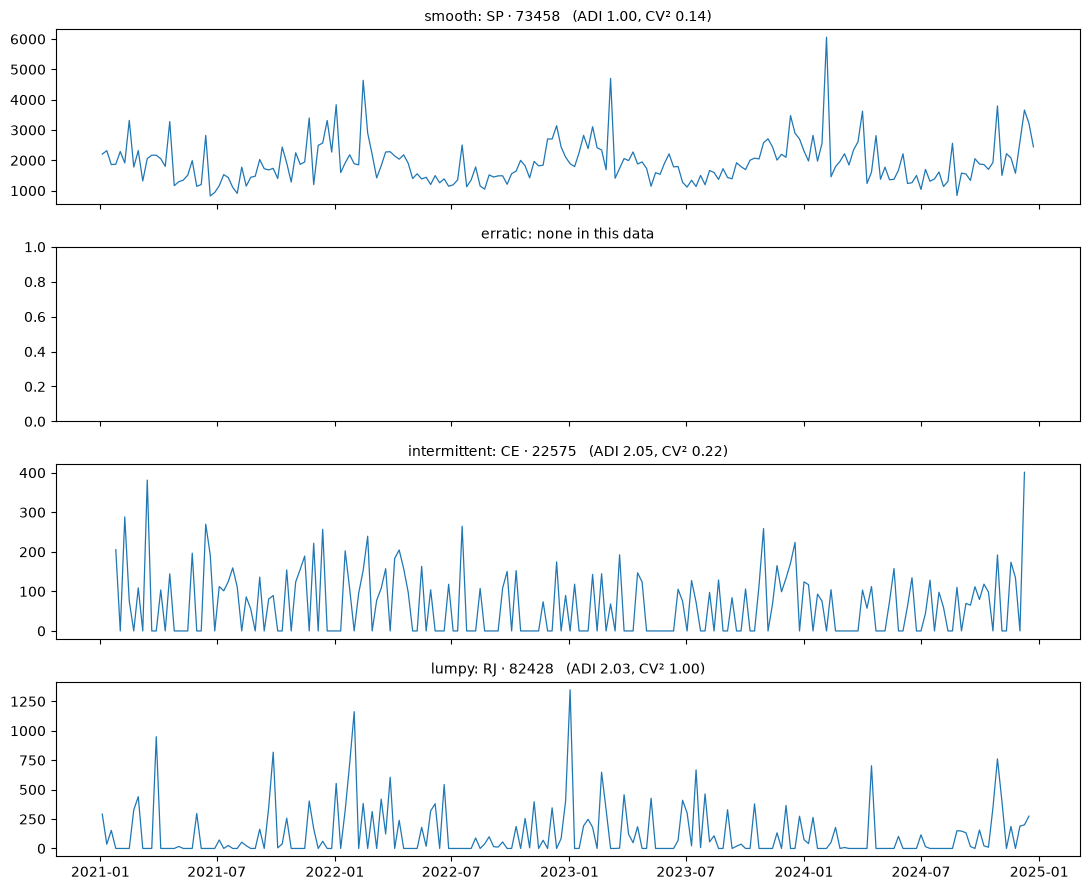

In [42]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for ax, seg in zip(axes, ["smooth", "erratic", "intermittent", "lumpy"]):
    if (stats["segment"] == seg).any():
        prov, sku = stats[stats["segment"] == seg].sort_values("total_hl", ascending=False).index[0]
        s = sales_weekly[(sales_weekly["province"] == prov) & (sales_weekly["sku_id"] == sku)]
        ax.plot(s["week_start"], s["volume_hl"], lw=0.9)
        r = stats.loc[(prov, sku)]
        ax.set_title(f"{seg}: {prov} · {sku}   (ADI {r.adi:.2f}, CV² {r.cv2:.2f})", fontsize=10)
    else:
        ax.set_title(f"{seg}: none in this data", fontsize=10)
plt.tight_layout()
plt.show()


In [43]:
check = stats.join(series.set_index(["province", "sku_id"])[["sparse", "order_prob", "container", "base_hl_week"]])
mismatch = check[(check["sparse"] & (check["segment"] == "smooth")) |
                 (~check["sparse"] & check["segment"].isin(["intermittent", "lumpy"]))]
mismatch[["segment", "sparse", "order_prob", "container", "base_hl_week", "adi", "cv2", "n_sales"]]


,,segment,sparse,order_prob,container,base_hl_week,adi,cv2,n_sales
province,sku_id,,,,,,,,


In [44]:
from demandfcst.synthetic import catalog as catmod

cat = catmod.build_catalog(SEED)
print("SKUs identical:", cat["skus"].equals(skus))

cols = ["province", "sku_id", "base_hl_week", "trend_per_year", "season_amp"]
print("series:", len(cat["series"]), "| first settings identical:",
      cat["series"][cols].equals(series[cols].reset_index(drop=True)))
print(cat["series"]["designed_segment"].value_counts())


SKUs identical: True
series: 231 | first settings identical: True
designed_segment
smooth          178
lumpy            28
intermittent     14
erratic          11
Name: count, dtype: int64


In [45]:
path = catmod.save_params(cat, ROOT / "data/generator/generator_params.json",
                          seed=SEED, history_start=HISTORY_START, history_end=HISTORY_END)
print(path, "|", path.stat().st_size // 1024, "KB")

cat2, meta = catmod.load_params(path)
print(meta)
print(cat2["series"].shape, "| launched SKUs:", cat2["skus"]["launch_date"].notna().sum())
cat2["series"].head(3)


c:\Harish\demand_forecasting\demand_forecasting_abi\demand_forecasting\data\generator\generator_params.json | 92 KB
{'seed': 42, 'history_start': '2021-01-01', 'history_end': '2024-12-29'}
(231, 12) | launched SKUs: 4


,series_num,province,sku_id,base_hl_week,trend_per_year,season_amp,weather_beta,promo_rate,designed_segment,order_prob,noise_cv,week_cv
0,0,SP,73458,1671.9,0.036,0.285,0.022,0.000,smooth,1.0,0.32,0.0
1,1,SP,66657,690.4,-0.010,0.262,0.023,0.000,smooth,1.0,0.36,0.0
2,2,SP,84879,842.5,-0.051,0.254,0.031,0.072,smooth,1.0,0.35,0.0


In [46]:
from demandfcst.synthetic import weather as wmod
src = ROOT / "data/raw/source/weather_source.csv"

pw = wmod.weekly_weather(src, provinces, HISTORY_START, HISTORY_END, SEED)
print(pw.shape, "| synthetic rows:", pw["is_synthetic"].sum())

# 1) real weeks must match the notebook exactly
nb = weather.loc[~weather["is_synthetic"], ["province", "week_start", "temp_avg_c", "anomaly_c"]]
m = pw[~pw["is_synthetic"]].merge(nb, on=["province", "week_start"], suffixes=("_pkg", "_nb"))
print("real weeks:", len(m), "| temps equal:", np.allclose(m["temp_avg_c_pkg"], m["temp_avg_c_nb"]),
      "| anomalies equal:", np.allclose(m["anomaly_c_pkg"], m["anomaly_c_nb"]))

# 2) one week generated alone = the same week inside the full range
one = wmod.weekly_weather(src, provinces, pd.Timestamp("2024-12-16"), pd.Timestamp("2024-12-22"), SEED)
m2 = one.merge(pw, on=["province", "week_start"], suffixes=("_one", "_full"))
print("alone vs full:", len(one), "rows | identical:", np.allclose(m2["temp_avg_c_one"], m2["temp_avg_c_full"]))

# 3) a 2025 week, as the release script will ask for it
wmod.weekly_weather(src, provinces, pd.Timestamp("2025-01-06"), pd.Timestamp("2025-01-12"), SEED)[
    ["province", "week_start", "temp_avg_c", "anomaly_c", "is_synthetic"]]


(1881, 8) | synthetic rows: 72
real weeks: 1809 | temps equal: True | anomalies equal: True
alone vs full: 9 rows | identical: True


,province,week_start,temp_avg_c,anomaly_c,is_synthetic
0,BA,2025-01-06,25.29,-0.82,True
1,CE,2025-01-06,26.16,-0.17,True
2,MG,2025-01-06,22.24,-2.30,True
3,PE,2025-01-06,26.86,0.43,True
4,PR,2025-01-06,26.34,2.68,True
5,RJ,2025-01-06,24.74,-2.35,True
6,RS,2025-01-06,22.70,-2.84,True
7,SC,2025-01-06,28.56,2.70,True
8,SP,2025-01-06,25.19,0.04,True


In [47]:
import time
from demandfcst.synthetic import demand as dmod

t0 = time.perf_counter()
pkg_sales, pkg_promos = dmod.generate_daily(HISTORY_START, HISTORY_END, cat, pw, SEED)
print(f"generated in {time.perf_counter() - t0:.1f}s | rows: {len(pkg_sales):,} | promotions: {len(pkg_promos):,}")

print("columns:", list(pkg_sales.columns))
print("dates:", pkg_sales["date"].min().date(), "→", pkg_sales["date"].max().date(),
      "| Sundays:", (pkg_sales["date"].dt.day_of_week == 6).sum(),
      "| duplicates:", pkg_sales.duplicated(["province", "sku_id", "date"]).sum(),
      "| min volume:", pkg_sales["volume_hl"].min())
print("total HL — package:", round(pkg_sales["volume_hl"].sum()), "| notebook:", round(sales_daily["volume_hl"].sum()))


generated in 2.5s | rows: 223,125 | promotions: 1,856
columns: ['date', 'province', 'sku_id', 'volume_hl']
dates: 2021-01-01 → 2024-12-28 | Sundays: 0 | duplicates: 0 | min volume: 0.001
total HL — package: 8983295 | notebook: 9034776


In [48]:
one, _ = dmod.generate_daily(pd.Timestamp("2024-12-16"), pd.Timestamp("2024-12-22"), cat, pw, SEED)
same_week = pkg_sales[(pkg_sales["date"] >= "2024-12-16") & (pkg_sales["date"] <= "2024-12-22")].reset_index(drop=True)
print("rows:", len(one), "vs", len(same_week), "| identical:", one.equals(same_week))


rows: 1089 vs 1089 | identical: True


In [50]:
from demandfcst.synthetic import calendar as calmod


sd = pkg_sales.assign(week_start=calmod.week_start(pkg_sales["date"]))
wk = sd.groupby(["province", "sku_id", "week_start"], as_index=False)["volume_hl"].sum()
wk = wk[(wk["week_start"] >= "2021-01-04") & (wk["week_start"] <= "2024-12-23")]

span = wk.groupby(["province", "sku_id"])["week_start"].agg(["min", "max"])
n_weeks = (span["max"] - span["min"]).dt.days // 7 + 1                  # active life, in weeks
by_series = wk.groupby(["province", "sku_id"])["volume_hl"]
st = pd.DataFrame({"adi": n_weeks / by_series.size(),
                   "cv2": (by_series.std() / by_series.mean()) ** 2})
st["segment"] = np.select([(st["adi"] < 1.32) & (st["cv2"] < 0.49), st["adi"] < 1.32, st["cv2"] < 0.49],
                          ["smooth", "erratic", "intermittent"], default="lumpy")

designed = cat["series"].set_index(["province", "sku_id"])["designed_segment"]
pd.crosstab(st["segment"], designed.reindex(st.index), margins=True)


designed_segment,erratic,intermittent,lumpy,smooth,All
segment,,,,,
erratic,11,0,0,0,11
intermittent,0,14,0,0,14
lumpy,0,0,28,0,28
smooth,0,0,0,178,178
All,11,14,28,178,231


In [1]:
import pandas as pd
from demandfcst import config, storage
from demandfcst.synthetic import catalog as catmod, demand as dmod, release as relmod, weather as wmod

loc = config.locations()                                   # storage = "s3" now
dates = relmod.drop_dates(loc["landing"], "sellin_daily")
print(loc["landing"])
print(len(dates), "drops:", dates[0].date(), "→", dates[-1].date())

last = dates[-1]
released = pd.read_csv(storage.join(landing_dir := storage.join(loc["landing"], "sellin_daily",
                                                                f"ingest_date={last:%Y-%m-%d}"), "part.csv"),
                       dtype={"province": str, "sku_id": str}, parse_dates=["date"])

cat_p, meta = catmod.load_params(storage.join(loc["generator"], "generator_params.json"))
start, end = last - pd.Timedelta(days=27), last
wx = wmod.weekly_weather(storage.join(loc["generator"], "weather_source.csv"),
                         cat_p["provinces"], start, end, meta["seed"])
continuous, _ = dmod.generate_daily(start, end, cat_p, wx, meta["seed"])
week = continuous[continuous["date"].between(last - pd.Timedelta(days=6), last)].reset_index(drop=True)

pd.testing.assert_frame_equal(released, week, check_dtype=False)
print(len(released), "rows: the week released into S3 == continuous generation ✅")


s3://demandfcst-harish-1405/landing
6 drops: 2025-01-05 → 2025-02-09
1094 rows: the week released into S3 == continuous generation ✅
